<a href="https://colab.research.google.com/github/stivenramosnieto-creator/entregables-stiven-ramos-nieto/blob/main/Taller_Aprendizaje_No_Supervisado_Steam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importar las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el archivo CSV desde el computador

from google.colab import files
archivos = files.upload()

Saving vdeojuegos de steam.csv to vdeojuegos de steam.csv


In [ ]:
# Leer el archivo CSV sin encabezados originales

nombre_archivo = next(iter(archivos))

df = pd.read_csv(
    nombre_archivo,
    header=None,
    names=["user_id", "game", "behavior", "value", "extra"]
)

# Mostrar las primeras filas

df.head()

,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [ ]:

# 1. EXPLORACIÓN DE LOS DATOS


# 1. Dimensiones del dataset

print("Dimensiones del dataset:")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

# 2. Tipos de variables

print("\nTipos de variables:")
print(df.dtypes)

# 3. Valores nulos

print("\nValores nulos por columna:")
print(df.isnull().sum())

# 4. Registros duplicados

print("\nCantidad de registros duplicados:")
print(df.duplicated().sum())

# 5. Estadísticos descriptivos

print("\nEstadísticos descriptivos:")
display(df.describe(include="all"))

# 6. Cantidad de registros por tipo de comportamiento

print("\nTipos de comportamiento:")
print(df["behavior"].value_counts())

Dimensiones del dataset:
Filas: 200000
Columnas: 5

Tipos de variables:
user_id       int64
game         object
behavior     object
value       float64
extra         int64
dtype: object

Valores nulos por columna:
user_id     0
game        0
behavior    0
value       0
extra       0
dtype: int64

Cantidad de registros duplicados:
707

Estadísticos descriptivos:


,user_id,game,behavior,value,extra
count,2.000000e+05,200000,200000,200000.000000,200000.0
unique,NaN,5155,2,NaN,NaN
top,NaN,Dota 2,purchase,NaN,NaN
freq,NaN,9682,129511,NaN,NaN
mean,1.036559e+08,NaN,NaN,17.874384,0.0
std,7.208074e+07,NaN,NaN,138.056952,0.0
min,5.250000e+03,NaN,NaN,0.100000,0.0
25%,4.738420e+07,NaN,NaN,1.000000,0.0
50%,8.691201e+07,NaN,NaN,1.000000,0.0
75%,1.542309e+08,NaN,NaN,1.300000,0.0



Tipos de comportamiento:
behavior
purchase    129511
play         70489
Name: count, dtype: int64


| Elemento                         | Resultado |
| -------------------------------- | --------: |
| Filas                            |   200.000 |
| Columnas                         |         5 |
| Videojuegos diferentes           |     5.155 |
| Registros de compra (`purchase`) |   129.511 |
| Registros de juego (`play`)      |    70.489 |
| Valores nulos                    |         0 |
| Registros duplicados exactos     |       707 |


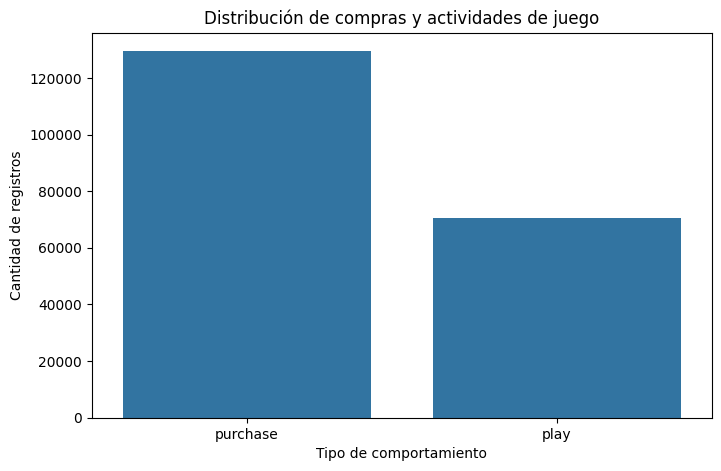

In [ ]:

# GRÁFICO 1: TIPOS DE COMPORTAMIENTO


plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="behavior"
)

plt.title("Distribución de compras y actividades de juego")
plt.xlabel("Tipo de comportamiento")
plt.ylabel("Cantidad de registros")

plt.show()

In [ ]:

# 2. PREPARACIÓN DE LOS DATOS


# Revisar las primeras filas
display(df.head(10))

# Revisar los nombres de las columnas
print("Columnas del dataset:")
print(df.columns.tolist())

# Revisar los tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

# Revisar las categorías de comportamiento
print("\nCategorías de comportamiento:")
print(df["behavior"].value_counts())

# Revisar ejemplos de cada categoría
print("\nEjemplos de registros de compra:")
display(df[df["behavior"] == "purchase"].head())

print("\nEjemplos de registros de juego:")
display(df[df["behavior"] == "play"].head())

,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0
5,151603712,Spore,play,14.9,0
6,151603712,Fallout New Vegas,purchase,1.0,0
7,151603712,Fallout New Vegas,play,12.1,0
8,151603712,Left 4 Dead 2,purchase,1.0,0
9,151603712,Left 4 Dead 2,play,8.9,0


Columnas del dataset:
['user_id', 'game', 'behavior', 'value', 'extra']

Tipos de datos:
user_id       int64
game         object
behavior     object
value       float64
extra         int64
dtype: object

Categorías de comportamiento:
behavior
purchase    129511
play         70489
Name: count, dtype: int64

Ejemplos de registros de compra:


,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
2,151603712,Fallout 4,purchase,1.0,0
4,151603712,Spore,purchase,1.0,0
6,151603712,Fallout New Vegas,purchase,1.0,0
8,151603712,Left 4 Dead 2,purchase,1.0,0



Ejemplos de registros de juego:


,user_id,game,behavior,value,extra
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
3,151603712,Fallout 4,play,87.0,0
5,151603712,Spore,play,14.9,0
7,151603712,Fallout New Vegas,play,12.1,0
9,151603712,Left 4 Dead 2,play,8.9,0


In [ ]:
# Crear una copia del dataset original
df_limpio = df.copy()

# Revisar si la columna extra contiene únicamente ceros
print("Valores únicos de la columna extra:")
print(df_limpio["extra"].unique())

# Eliminar la columna extra
df_limpio = df_limpio.drop(columns=["extra"])

# Contar duplicados antes de eliminarlos
duplicados_antes = df_limpio.duplicated().sum()

print("\nDuplicados antes de la limpieza:", duplicados_antes)

# Eliminar registros duplicados exactos
df_limpio = df_limpio.drop_duplicates().copy()

# Mostrar resultados
print("\nDimensiones después de la limpieza:")
print(df_limpio.shape)

print("\nDuplicados después de la limpieza:")
print(df_limpio.duplicated().sum())

# Mostrar las primeras filas
display(df_limpio.head())

Valores únicos de la columna extra:
[0]

Duplicados antes de la limpieza: 707

Dimensiones después de la limpieza:
(199293, 4)

Duplicados después de la limpieza:
0


,user_id,game,behavior,value
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0
1,151603712,The Elder Scrolls V Skyrim,play,273.0
2,151603712,Fallout 4,purchase,1.0
3,151603712,Fallout 4,play,87.0
4,151603712,Spore,purchase,1.0


| Variable           | Significado                                     |
| ------------------ | ----------------------------------------------- |
| `juegos_comprados` | Cantidad de registros de compra del usuario.    |
| `juegos_jugados`   | Cantidad de videojuegos con registros de juego. |
| `horas_totales`    | Suma de las horas de juego registradas.         |
| `promedio_horas`   | Promedio de horas por videojuego jugado.        |


In [ ]:

# CREACIÓN DEL PERFIL DE CADA USUARIO


# Separar compras y actividades de juego
compras = df_limpio[df_limpio["behavior"] == "purchase"]
juegos = df_limpio[df_limpio["behavior"] == "play"]

# Calcular la cantidad de juegos comprados por usuario
compras_usuario = compras.groupby("user_id").agg(
    juegos_comprados=("game", "nunique")
)

# Calcular estadísticas de juego por usuario
juegos_usuario = juegos.groupby("user_id").agg(
    juegos_jugados=("game", "nunique"),
    horas_totales=("value", "sum"),
    promedio_horas=("value", "mean")
)

# Unir la información de compras y juego
perfil_usuarios = compras_usuario.join(
    juegos_usuario,
    how="outer"
).fillna(0)

# Mostrar los primeros perfiles
display(perfil_usuarios.head())

# Revisar las dimensiones
print("Cantidad de usuarios:", perfil_usuarios.shape[0])
print("Cantidad de variables:", perfil_usuarios.shape[1])

,juegos_comprados,juegos_jugados,horas_totales,promedio_horas
user_id,,,,
5250,21,6.0,225.5,37.583333
76767,36,20.0,1227.0,61.350000
86540,82,15.0,255.0,17.000000
103360,10,0.0,0.0,0.000000
144736,8,1.0,0.1,0.100000


Cantidad de usuarios: 12393
Cantidad de variables: 4


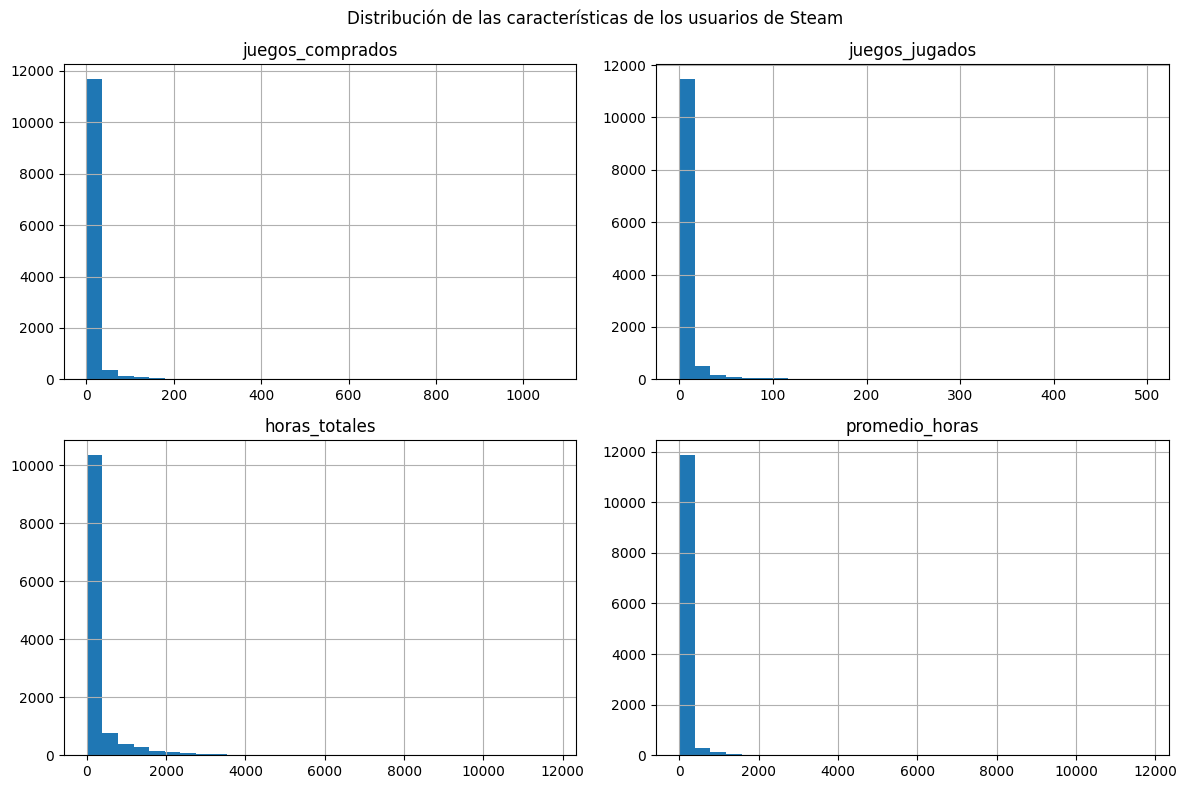

In [ ]:

# DISTRIBUCIÓN DE LAS VARIABLES DE USUARIO


variables = [
    "juegos_comprados",
    "juegos_jugados",
    "horas_totales",
    "promedio_horas"
]

perfil_usuarios[variables].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle(
    "Distribución de las características de los usuarios de Steam"
)

plt.tight_layout()
plt.show()

Preparación de los datos: Se realizó una limpieza inicial del conjunto de datos, eliminando una columna constante que no aportaba información relevante y los registros completamente duplicados, bajo el supuesto de que correspondían a duplicaciones accidentales. Posteriormente, se agruparon los registros por usuario para construir variables que describen su comportamiento, como la cantidad de juegos comprados, la cantidad de juegos jugados, las horas totales y el promedio de horas por videojuego. Esta transformación permite representar a cada usuario mediante características numéricas que pueden utilizarse en un algoritmo de clustering.

In [ ]:
# Seleccionar las variables que utilizaremos para agrupar usuarios
variables = [
    "juegos_comprados",
    "juegos_jugados",
    "horas_totales",
    "promedio_horas"
]

# Revisar las estadísticas de las variables
print("Estadísticas descriptivas:")
display(perfil_usuarios[variables].describe().round(2))

# Revisar qué tan asimétricos son los datos
print("\nAsimetría de las variables:")
print(perfil_usuarios[variables].skew().round(2))

Estadísticas descriptivas:


,juegos_comprados,juegos_jugados,horas_totales,promedio_horas
count,12393.00,12393.00,12393.00,12393.00
mean,10.39,5.69,278.01,74.32
std,35.64,17.08,760.27,283.75
min,1.00,0.00,0.00,0.00
25%,1.00,1.00,1.30,1.10
50%,2.00,1.00,13.50,7.90
75%,6.00,3.00,155.60,39.00
max,1068.00,498.00,11754.00,11754.00



Asimetría de las variables:
juegos_comprados    10.75
juegos_jugados       8.87
horas_totales        5.50
promedio_horas      15.13
dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Seleccionar las variables para el modelo
variables = [
    "juegos_comprados",
    "juegos_jugados",
    "horas_totales",
    "promedio_horas"
]

# Aplicar transformación logarítmica
X_log = np.log1p(perfil_usuarios[variables])

# Estandarizar las variables
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

# Convertir el resultado en un DataFrame
X_escalado = pd.DataFrame(
    X_escalado,
    columns=variables,
    index=perfil_usuarios.index
)

# Mostrar los resultados
print("Primeras cinco filas de los datos preparados:")
display(X_escalado.head())

print("\nPromedio de las variables estandarizadas:")
print(X_escalado.mean().round(2))

print("\nDesviación estándar de las variables:")
print(X_escalado.std().round(2))

Primeras cinco filas de los datos preparados:


,juegos_comprados,juegos_jugados,horas_totales,promedio_horas
user_id,,,,
5250,1.516955,0.843982,0.967274,0.675150
76767,2.006473,2.010694,1.661647,0.933420
86540,2.767218,1.721904,1.017566,0.264857
103360,0.864283,-1.222550,-1.260254,-1.290528
144736,0.675330,-0.486437,-1.221103,-1.239239



Promedio de las variables estandarizadas:
juegos_comprados    0.0
juegos_jugados     -0.0
horas_totales      -0.0
promedio_horas      0.0
dtype: float64

Desviación estándar de las variables:
juegos_comprados    1.0
juegos_jugados      1.0
horas_totales       1.0
promedio_horas      1.0
dtype: float64


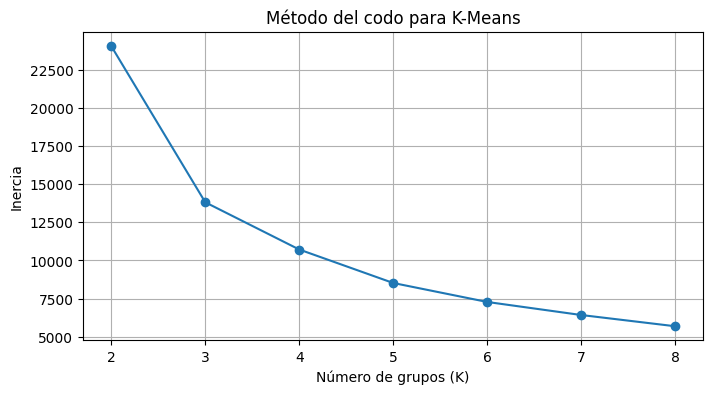

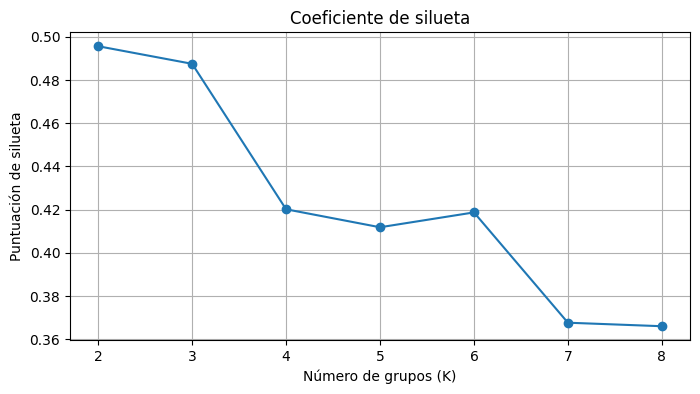

K = 2: silueta = 0.4956
K = 3: silueta = 0.4875
K = 4: silueta = 0.4201
K = 5: silueta = 0.4118
K = 6: silueta = 0.4187
K = 7: silueta = 0.3676
K = 8: silueta = 0.3660


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Evaluar entre 2 y 8 grupos
valores_k = range(2, 9)

inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas))

# Gráfica del método del codo
plt.figure(figsize=(8, 4))
plt.plot(list(valores_k), inercias, marker="o")
plt.title("Método del codo para K-Means")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

# Gráfica del coeficiente de silueta
plt.figure(figsize=(8, 4))
plt.plot(list(valores_k), siluetas, marker="o")
plt.title("Coeficiente de silueta")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Puntuación de silueta")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

# Mostrar puntuaciones
for k, puntuacion in zip(valores_k, siluetas):
    print(f"K = {k}: silueta = {puntuacion:.4f}")

In [ ]:
from sklearn.cluster import KMeans

# Crear el modelo con 2 grupos
modelo_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Asignar un grupo a cada usuario
perfil_usuarios["cluster"] = modelo_kmeans.fit_predict(X_escalado)

# Contar los usuarios de cada grupo
print("Cantidad de usuarios por grupo:")
print(perfil_usuarios["cluster"].value_counts().sort_index())

# Mostrar los primeros resultados
display(perfil_usuarios.head())

Cantidad de usuarios por grupo:
cluster
0    4418
1    7975
Name: count, dtype: int64


,juegos_comprados,juegos_jugados,horas_totales,promedio_horas,cluster
user_id,,,,,
5250,21,6.0,225.5,37.583333,0
76767,36,20.0,1227.0,61.350000,0
86540,82,15.0,255.0,17.000000,0
103360,10,0.0,0.0,0.000000,1
144736,8,1.0,0.1,0.100000,1


| Grupo     | Cantidad de usuarios | Porcentaje aproximado |
| --------- | -------------------: | --------------------: |
| Cluster 0 |                4.418 |               35,65 % |
| Cluster 1 |                7.975 |               64,35 % |
| **Total** |           **12.393** |             **100 %** |


In [ ]:
# Calcular el promedio de las variables para cada grupo
resumen_clusters = perfil_usuarios.groupby("cluster")[
    [
        "juegos_comprados",
        "juegos_jugados",
        "horas_totales",
        "promedio_horas"
    ]
].mean().round(2)

print("Características promedio de cada grupo:")
display(resumen_clusters)

Características promedio de cada grupo:


,juegos_comprados,juegos_jugados,horas_totales,promedio_horas
cluster,,,,
0,25.38,13.88,762.25,193.51
1,2.09,1.15,9.75,8.29


 Cluster 0: usuarios de alta actividad

Este grupo tiene aproximadamente 4.418 usuarios, equivalentes al 35,65 % de la muestra.

Sus características son:

Compran, en promedio, 25,38 juegos.
Registran aproximadamente 13,88 juegos jugados.
Acumulan un promedio de 762,25 horas totales de juego.
Presentan un promedio de 193,51 horas por juego jugado.

Interpretación: son usuarios con una actividad de juego considerable y un catálogo de compras más amplio. Podrían ser un segmento interesante para estrategias de fidelización, recomendaciones personalizadas y promociones de juegos relacionados con sus preferencias.

 Cluster 1: usuarios de menor actividad registrada

Este grupo contiene aproximadamente 7.975 usuarios, equivalentes al 64,35 % de la muestra.

Sus características son:

Compran, en promedio, 2,09 juegos.
Registran aproximadamente 1,15 juegos jugados.
Acumulan un promedio de 9,75 horas totales.
Presentan un promedio de 8,29 horas por juego jugado.

Interpretación: estos usuarios muestran menos compras y menos horas de juego registradas. Podrían ser candidatos para campañas de bienvenida, recomendaciones de juegos y promociones orientadas a incentivar una mayor participación.

Importante: hablamos de actividad registrada en este dataset; no podemos asegurar que sean usuarios ocasionales en la actualidad, porque no estamos analizando fechas recientes ni toda su actividad histórica.

De acuerdo con los resultados, una empresa podría diseñar estas estrategias:

Segmento	Estrategia recomendada	Objetivo
Cluster 0	Recompensas por fidelidad y recomendaciones personalizadas	Mantener el interés y fomentar nuevas compras.
Cluster 1	Promociones de entrada, descuentos y recomendaciones de juegos populares	Incentivar la participación y las compras

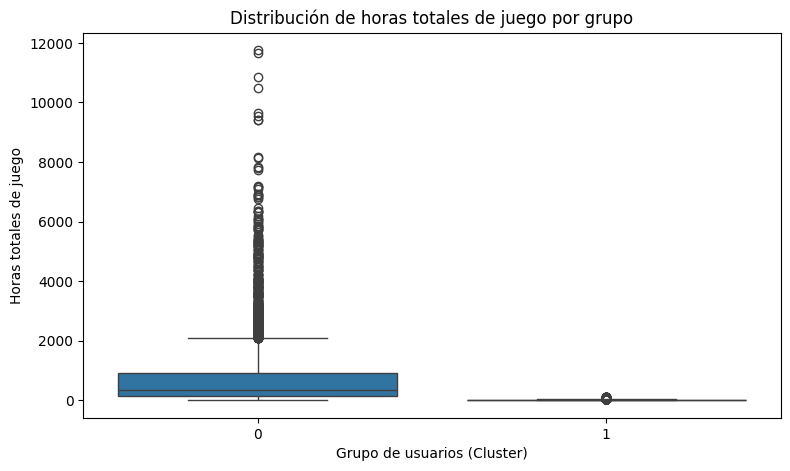

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparar las horas totales de juego por grupo
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=perfil_usuarios,
    x="cluster",
    y="horas_totales"
)

plt.title("Distribución de horas totales de juego por grupo")
plt.xlabel("Grupo de usuarios (Cluster)")
plt.ylabel("Horas totales de juego")

plt.show()

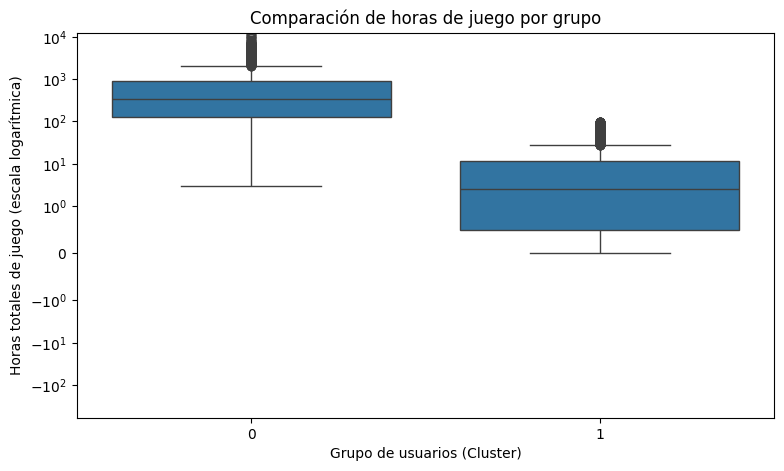

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=perfil_usuarios,
    x="cluster",
    y="horas_totales"
)

plt.yscale("symlog", linthresh=1)

plt.title("Comparación de horas de juego por grupo")
plt.xlabel("Grupo de usuarios (Cluster)")
plt.ylabel("Horas totales de juego (escala logarítmica)")

plt.show()

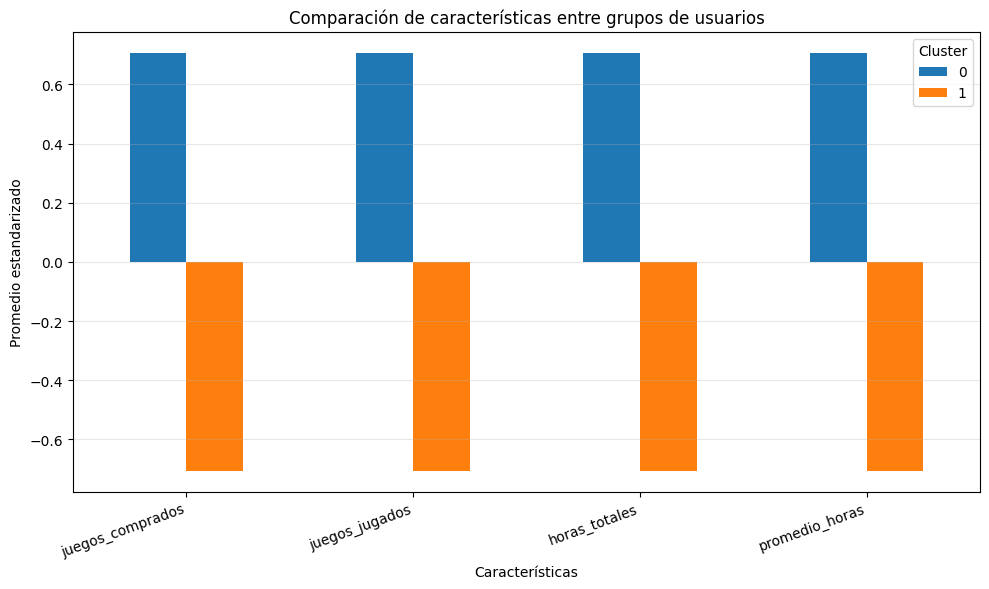

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calcular los promedios de cada grupo
variables = [
    "juegos_comprados",
    "juegos_jugados",
    "horas_totales",
    "promedio_horas"
]

resumen_clusters = perfil_usuarios.groupby("cluster")[variables].mean()

# Estandarizar los promedios para facilitar la comparación visual
resumen_visual = (
    resumen_clusters - resumen_clusters.mean()
) / resumen_clusters.std()

# Crear gráfica comparativa
resumen_visual.T.plot(kind="bar", figsize=(10, 6))

plt.title("Comparación de características entre grupos de usuarios")
plt.xlabel("Características")
plt.ylabel("Promedio estandarizado")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

| Característica    | Cluster 0             | Cluster 1               |
| ----------------- | --------------------- | ----------------------- |
| Juegos comprados  | Mayor cantidad        | Menor cantidad          |
| Juegos jugados    | Mayor cantidad        | Menor cantidad          |
| Horas totales     | Más horas registradas | Menos horas registradas |
| Promedio de horas | Mayor promedio        | Menor promedio          |


Conclusiones del análisis

El análisis del conjunto de datos de Steam permitió identificar patrones de comportamiento entre los usuarios a partir de sus compras de videojuegos, la cantidad de juegos registrados como jugados y sus horas de juego.

Mediante el algoritmo K-Means se identificaron dos grupos de usuarios con características diferenciadas. El primer grupo presenta una mayor actividad registrada, con más juegos comprados, más juegos jugados y una mayor cantidad de horas acumuladas. El segundo grupo presenta niveles inferiores en estas variables.

La preparación de los datos, mediante una transformación logarítmica y la estandarización de las variables, permitió adecuar la información para aplicar el algoritmo de agrupamiento. La evaluación del coeficiente de silueta favoreció la elección inicial de dos grupos entre las alternativas evaluadas.

Los resultados muestran cómo las técnicas de ciencia de datos pueden ayudar a comprender el comportamiento de los usuarios y proporcionar información útil para la toma de decisiones empresariales.

| Grupo     | Recomendación                                                                    | Objetivo                                                        |
| --------- | -------------------------------------------------------------------------------- | --------------------------------------------------------------- |
| Cluster 0 | Ofrecer recompensas por fidelidad y recomendaciones personalizadas.              | Mantener el interés de los usuarios y fomentar nuevas compras.  |
| Cluster 1 | Diseñar promociones de entrada y recomendar juegos acordes con sus preferencias. | Incentivar la participación y explorar oportunidades de compra. |


Recomendación adicional: sería útil contar con información sobre las fechas de compra, el gasto real, las preferencias por género de videojuegos y la evolución de la actividad de cada usuario. Estos datos permitirían diseñar campañas más precisas.

6. Recomendaciones de negocio basadas en los segmentos de usuarios
6.1. Análisis de los resultados

Mediante el algoritmo K-Means se identificaron dos segmentos de usuarios con diferentes niveles de actividad registrada en la plataforma Steam.

Clúster 0: Usuarios con alta actividad registrada. Este grupo está conformado por 4.418 usuarios, equivalentes al 35,65 % del total analizado. En promedio, estos usuarios tienen 25,38 juegos comprados, 13,88 juegos registrados como jugados y 762,25 horas totales de juego.
Clúster 1: Usuarios con baja actividad registrada. Este grupo está conformado por 7.975 usuarios, equivalentes al 64,35 % del total analizado. En promedio, estos usuarios tienen 2,09 juegos comprados, 1,15 juegos registrados como jugados y 9,75 horas totales de juego.

Estos resultados muestran diferencias importantes en el comportamiento registrado de los usuarios. Por lo tanto, Steam podría diseñar estrategias comerciales específicas para cada segmento, en lugar de aplicar las mismas promociones a todos sus clientes.

Es importante aclarar que estos grupos representan niveles de actividad observados en los datos disponibles. Como el conjunto de datos no contiene fechas, no podemos asegurar que los usuarios del segundo grupo estén actualmente inactivos o que jueguen de manera ocasional.

6.2. Estrategias comerciales para cada segmento
Segmento	Estrategia propuesta	Objetivo empresarial
Clúster 0: alta actividad registrada	Programa de fidelización con recompensas, descuentos exclusivos y beneficios por compras recurrentes.	Conservar a los usuarios de mayor actividad y fortalecer su relación con la plataforma.
Clúster 0: alta actividad registrada	Recomendaciones personalizadas de videojuegos relacionados con sus intereses y hábitos de juego.	Incentivar nuevas compras y mejorar la experiencia del usuario.
Clúster 0: alta actividad registrada	Ofertas especiales para lanzamientos, expansiones y contenidos adicionales.	Promover nuevas oportunidades de compra entre usuarios que ya presentan una actividad elevada.
Clúster 1: baja actividad registrada	Campañas de bienvenida y promociones para facilitar la compra de nuevos videojuegos.	Motivar una mayor participación y estimular futuras compras.
Clúster 1: baja actividad registrada	Recomendaciones de videojuegos populares o de bajo costo, adaptadas a los intereses de cada usuario cuando esta información esté disponible.	Facilitar el descubrimiento de juegos y reducir las barreras de entrada a nuevas compras.
Clúster 1: baja actividad registrada	Encuestas breves o análisis de interacción para conocer sus preferencias y posibles razones de su baja actividad registrada.	Obtener información que permita diseñar estrategias de reactivación más pertinentes.
6.3. Priorización de clientes y recursos de marketing

La segmentación también puede ayudar a Steam a distribuir mejor sus recursos de marketing.

Para el clúster 0, la empresa podría priorizar acciones de fidelización y personalización. Estos usuarios presentan una mayor cantidad de juegos comprados y jugados, así como más horas registradas. Por ello, sería conveniente evaluar campañas que fortalezcan su relación con la plataforma y promuevan nuevas compras.

Para el clúster 1, la prioridad podría ser incentivar la participación y comprender mejor sus necesidades. Las promociones de entrada, las recomendaciones relevantes y las comunicaciones personalizadas podrían ayudar a aumentar su interacción con la plataforma.

Sin embargo, las campañas deben evaluarse antes de implementarse a gran escala. Una mayor actividad registrada no garantiza automáticamente una mayor rentabilidad, ya que no disponemos de información completa sobre el dinero gastado por cada usuario ni sobre los costos de las promociones.

6.4. Información adicional que sería útil recopilar

Aunque el modelo permitió identificar dos grupos diferenciados, existen datos adicionales que podrían mejorar las recomendaciones comerciales.

Información adicional	¿Para qué serviría?
Fechas de compra y de última actividad	Identificar usuarios activos recientemente y detectar posibles abandonos.
Dinero gastado por usuario	Estimar el valor comercial de cada segmento y diseñar promociones rentables.
Géneros de videojuegos preferidos	Ofrecer recomendaciones más personalizadas según los intereses de cada usuario.
Historial de compras	Identificar patrones de consumo y posibles oportunidades de compra futura.
Interacción con promociones	Evaluar qué descuentos y campañas generan mejores resultados.
Valoraciones y opiniones sobre videojuegos	Comprender mejor las preferencias y mejorar las recomendaciones.

Esta información permitiría complementar la segmentación actual con estrategias más precisas y orientadas a resultados.

6.5. Indicadores para evaluar las estrategias

Para determinar si las recomendaciones funcionan, Steam podría medir los siguientes indicadores:

Tasa de conversión: porcentaje de usuarios que realizan una compra después de recibir una promoción.
Frecuencia de compra: número de compras realizadas por usuario durante un periodo determinado.
Retención de usuarios: proporción de usuarios que continúan utilizando la plataforma a lo largo del tiempo.
Respuesta a las recomendaciones: cantidad de usuarios que interactúan con los videojuegos sugeridos.
Ingresos por segmento: ingresos generados por cada grupo de usuarios durante un periodo específico.

Estos indicadores permitirían comparar los resultados antes y después de implementar las estrategias. También sería conveniente realizar pruebas controladas, por ejemplo, ofreciendo una promoción a un grupo de usuarios y comparando sus resultados con los de otro grupo similar que no la reciba.

De esta manera, la empresa podría identificar cuáles acciones generan beneficios reales y cuáles necesitan ajustes.

6.6. Conclusión de las recomendaciones de negocio

La segmentación realizada mediante K-Means demuestra cómo las técnicas de ciencia de datos pueden transformar los registros de una plataforma digital en información útil para la toma de decisiones estratégicas.

La identificación de dos grupos con diferentes niveles de actividad registrada permite proponer acciones diferenciadas: estrategias de fidelización y personalización para los usuarios con mayor actividad, y campañas orientadas a estimular la participación para aquellos con menor actividad registrada.

Además, la incorporación de información sobre fechas, gastos, preferencias y respuesta a las promociones permitiría mejorar la segmentación y evaluar con mayor precisión los resultados comerciales.

En conclusión, la ciencia de datos puede ayudar a Steam a comprender mejor a sus usuarios, optimizar sus campañas de marketing y diseñar estrategias comerciales basadas en evidencia, en lugar de depender únicamente de decisiones generales para toda su comunidad.